In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
data = {
    "Date": [
        "2024-01-05", "2024-01-12", "2024-02-08",
        "2024-02-15", "2024-03-10", "2024-03-18",
        "2024-04-06", "2024-04-20", "2024-05-09",
        "2024-05-22", "2024-06-11", "2024-06-25"
    ],
    "Medicine": [
        "Paracetamol", "Amoxicillin", "Ibuprofen",
        "Cetirizine", "Paracetamol", "Azithromycin",
        "Amoxicillin", "Ibuprofen", "Paracetamol",
        "Cetirizine", "Amoxicillin", "Azithromycin"
    ],
    "Category": [
        "Pain Relief", "Antibiotic", "Pain Relief",
        "Antihistamine", "Pain Relief", "Antibiotic",
        "Antibiotic", "Pain Relief", "Pain Relief",
        "Antihistamine", "Antibiotic", "Antibiotic"
    ],
    "Quantity": [120, 80, 150, 100, 180, 60, 140, 160, 200, 110, 170, 90],
    "Price": [0.15, 0.50, 0.20, 0.25, 0.15, 1.00,
              0.50, 0.20, 0.15, 0.25, 0.50, 1.00],
    "Type": [
        "Generic", "Branded", "Generic", "Branded",
        "Generic", "Branded", "Branded", "Generic",
        "Generic", "Branded", "Branded", "Branded"
    ]
}

df = pd.DataFrame(data)

df["Date"] = pd.to_datetime(df["Date"])
df["Sales"] = df["Quantity"] * df["Price"]

display(df)

,Date,Medicine,Category,Quantity,Price,Type,Sales
0,2024-01-05,Paracetamol,Pain Relief,120,0.15,Generic,18.0
1,2024-01-12,Amoxicillin,Antibiotic,80,0.50,Branded,40.0
2,2024-02-08,Ibuprofen,Pain Relief,150,0.20,Generic,30.0
3,2024-02-15,Cetirizine,Antihistamine,100,0.25,Branded,25.0
4,2024-03-10,Paracetamol,Pain Relief,180,0.15,Generic,27.0
5,2024-03-18,Azithromycin,Antibiotic,60,1.00,Branded,60.0
6,2024-04-06,Amoxicillin,Antibiotic,140,0.50,Branded,70.0
7,2024-04-20,Ibuprofen,Pain Relief,160,0.20,Generic,32.0
8,2024-05-09,Paracetamol,Pain Relief,200,0.15,Generic,30.0
9,2024-05-22,Cetirizine,Antihistamine,110,0.25,Branded,27.5


In [3]:
total_sales = df["Sales"].sum()
total_quantity = df["Quantity"].sum()

print("Total Revenue: $", round(total_sales, 2))
print("Total Quantity Sold:", total_quantity)

Total Revenue: $ 534.5
Total Quantity Sold: 1560


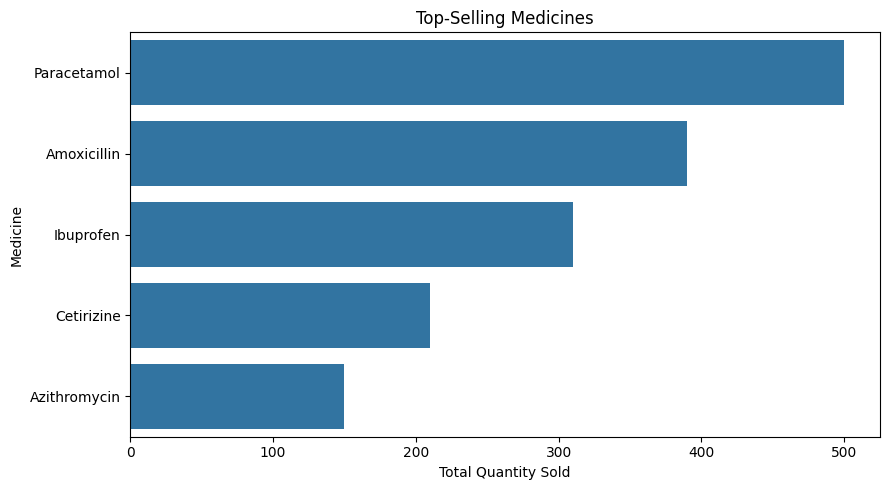

In [4]:
top_medicines = (
    df.groupby("Medicine")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(x=top_medicines.values, y=top_medicines.index)

plt.title("Top-Selling Medicines")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Medicine")
plt.tight_layout()
plt.show()

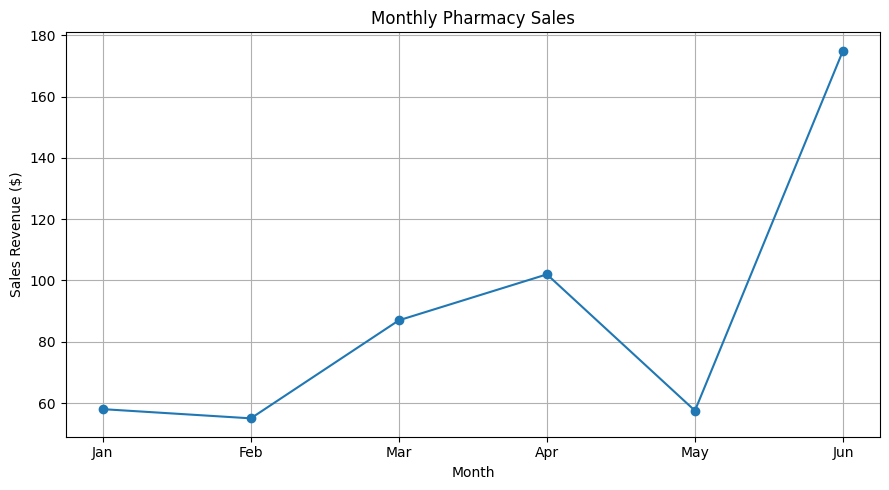

,Sales
Month,
Jan,58.0
Feb,55.0
Mar,87.0
Apr,102.0
May,57.5
Jun,175.0


In [5]:
df["Month"] = df["Date"].dt.strftime("%b")

monthly_sales = df.groupby("Month")["Sales"].sum()

month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
monthly_sales = monthly_sales.reindex(month_order)

plt.figure(figsize=(9, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Pharmacy Sales")
plt.xlabel("Month")
plt.ylabel("Sales Revenue ($)")
plt.grid(True)
plt.tight_layout()
plt.show()

display(monthly_sales)

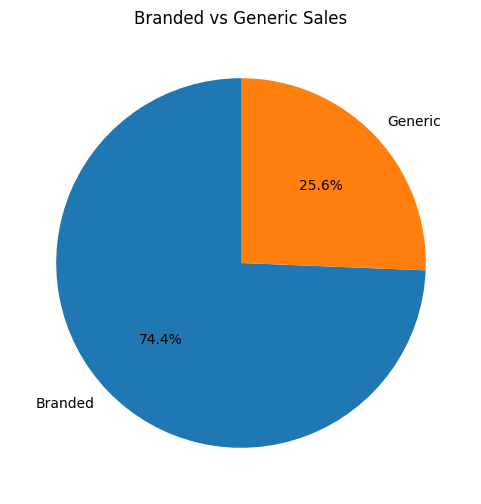

,Sales
Type,
Branded,397.5
Generic,137.0


In [6]:
type_sales = df.groupby("Type")["Sales"].sum()

plt.figure(figsize=(6, 6))
plt.pie(
    type_sales.values,
    labels=type_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Branded vs Generic Sales")
plt.show()

display(type_sales)

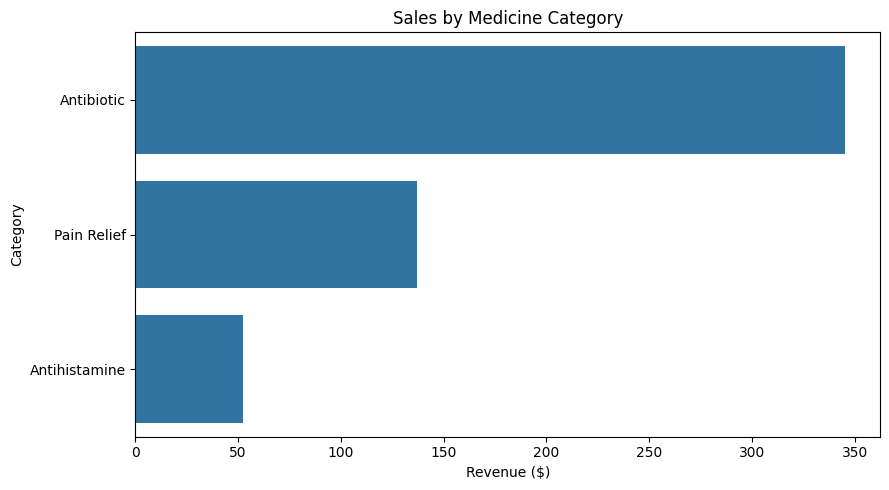

In [7]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=category_sales.values, y=category_sales.index)

plt.title("Sales by Medicine Category")
plt.xlabel("Revenue ($)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()